# Biomomentum preprocessing with optional PID steady-force segmentation

Read each TXT file in `data/Biomomentum_Data/txts/`. Set `ENABLE_STEADY_STATE_SEGMENTATION = True` to export only the detected steady-force interval, or `False` (default) to export the full recording, including loading and settling. Set `EXPORT_DURATION_S` to a number of seconds to limit either interval, or leave it as `None` to retain its full length. Run all cells in the **Dataprocess** environment with NumPy, pandas, Matplotlib, and IPython. Existing CSV files with matching names in `data/Biomomentum_Data/` are overwritten by the export cell.

Every output has exactly three ordered columns: **`Time, s`**, **`Indentation Position, mm`**, and **`Indentation Force, N`**. Use `Position (z), mm` as indentation and invert `Fz, N` so compression is positive. Reset **time only** to zero at the first retained sample; retain measured displacement and force, including PID oscillations. Do not filter, resample, or independently zero either measured signal.

A steady PID force can oscillate around its holding level. Detect the holding regime using a multi-period window mean and regression trend, with a separate allowance for force variation. Keep every sample within one continuous selected interval, including oscillation peaks and troughs. Review the plots before export. `_steady_state_manifest.csv` records the selected mode and original export boundaries, plus holding forces and detection settings when segmentation is enabled. Raw TXT files are read only.

In [73]:
import csv
import math
import sys

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from pathlib import Path

def find_project_root(start):
    # Support running from the project root, data_process, or this notebook directory.
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'Biomomentum_Data' / 'txts').is_dir():
            return candidate
    raise FileNotFoundError('Could not find data/Biomomentum_Data/txts. Start the notebook within the project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data' / 'txts'
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data'
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from creep_force_preprocessing import segment_force_steady_state, extract_indentation_cycles

SAMPLING_HZ = 200.0
ENABLE_STEADY_STATE_SEGMENTATION = True  # False keeps the full recording.
EXPORT_DURATION_S = 50.0  # Set to 60.0 for a 60-second export when available.
PID_STEADY_STATE_SETTINGS = dict(
    stability_window_s=2.0, stable_confirm_s=1.0, plateau_tail_s=5.0,
    level_tolerance_fraction=0.02, stable_std_fraction=0.05,
    stable_slope_fraction=0.01, release_guard_s=0.0, min_force_n=0.2,
)

# Used only with steady-state segmentation: positive delays, negative advances.
STEADY_START_OFFSET_S = 5.0
STEADY_END_OFFSET_S = 0.0

EXTRACT_COLUMNS = [
    'Time, s',
    'Position (z), mm',
    'Fz, N',
]

EXTRACT_COLUMNS_SIGNS = [
    1.0,
    1.0,
    -1.0,
]

OUTPUT_COLUMNS = [
    'Time, s',
    'Indentation Position, mm',
    'Indentation Force, N',
]

if len(EXTRACT_COLUMNS) != len(OUTPUT_COLUMNS):
    raise ValueError(f'EXTRACT_COLUMNS and OUTPUT_COLUMNS must have the same length. '
                     f'Found {len(EXTRACT_COLUMNS)} and {len(OUTPUT_COLUMNS)}.')

if len(EXTRACT_COLUMNS_SIGNS) != len(EXTRACT_COLUMNS):
    raise ValueError('EXTRACT_COLUMNS_SIGNS must contain one sign per extracted column.')
if any(not math.isfinite(sign) or sign not in (-1.0, 1.0) for sign in EXTRACT_COLUMNS_SIGNS):
    raise ValueError('Extraction signs must be finite and equal to +1 or -1.')
if EXTRACT_COLUMNS_SIGNS[0] != 1.0:
    raise ValueError('Keep the time sign at +1 so timestamps remain increasing.')

print(f'Input directory: {INPUT_DIR}')
print(f'Output directory: {OUTPUT_DIR}')
print(f'Steady-state segmentation: {ENABLE_STEADY_STATE_SEGMENTATION}')
print(f'Export duration: {EXPORT_DURATION_S} s')

Input directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data/txts
Output directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data
Steady-state segmentation: True
Export duration: 50.0 s


## Read data sections

Extract only the selected columns between `<DATA>` and `<END DATA>`, using the column names rather than axis order. Validate finite numeric values before applying the configured signs. Preserve all selected measurements for segmentation and comparison plots.

In [74]:
def read_biomomentum_txt(txt_path):
    txt_path = Path(txt_path)
    rows = []
    in_data = False
    header = None
    block_rows = 0

    def invalid(line_number, message):
        return ValueError(f'{txt_path.name}:{line_number}: {message}')

    with txt_path.open('r', encoding='utf-8-sig', newline='') as handle:
        for line_number, fields in enumerate(csv.reader(handle, delimiter='\t'), start=1):
            fields = [field.strip() for field in fields]
            if not fields or not any(fields):
                continue
            marker = fields[0]
            if marker == '<DATA>':
                if in_data:
                    raise invalid(line_number, 'The previous data section is missing <END DATA>.')
                in_data, header, block_rows = True, None, 0
                continue
            if not in_data:
                continue
            if marker == '<END DATA>':
                if header is None or block_rows == 0:
                    raise invalid(line_number, 'The data section is empty.')
                in_data = False
                continue
            if header is None:
                header = fields
                missing = [column for column in EXTRACT_COLUMNS if column not in header]
                if missing:
                    raise invalid(line_number, f'Missing columns: {missing}')
                if len(header) != len(set(header)):
                    raise invalid(line_number, 'The header contains duplicate column names.')
                column_indices = [header.index(column) for column in EXTRACT_COLUMNS]
                continue
            if len(fields) != len(header):
                raise invalid(line_number, f'Expected {len(header)} columns, found {len(fields)}.')
            selected = [fields[index] for index in column_indices]
            for column, value in zip(EXTRACT_COLUMNS, selected):
                try:
                    numeric_value = float(value)
                except ValueError as exc:
                    raise invalid(line_number, f'{column} contains a nonnumeric value: {value!r}') from exc
                if not math.isfinite(numeric_value):
                    raise invalid(line_number, f'{column} contains a nonfinite value: {value!r}')
            rows.append(selected)
            block_rows += 1

    if in_data:
        raise ValueError(f'{txt_path.name}: Reached the end of the file without finding <END DATA>.')
    if not rows:
        raise ValueError(f'{txt_path.name}: No valid <DATA> section was found.')
    
    for row in rows:
        for column, sign, value in zip(EXTRACT_COLUMNS, EXTRACT_COLUMNS_SIGNS, row):
            numeric_value = float(value)
            numeric_value *= sign
            row[EXTRACT_COLUMNS.index(column)] = numeric_value
    return rows

## Validate all input files

Read every TXT before selecting intervals or writing CSVs. Each recording is treated as one loading-and-hold interval. Require continuous 200 Hz timestamps; multiple concatenated data blocks with restarted times or missing samples raise an error instead of being joined into a false continuous record.

In [75]:
txt_files = sorted(
    path for path in INPUT_DIR.iterdir()
    if path.is_file() and path.suffix.lower() == '.txt'
)
if not txt_files:
    raise FileNotFoundError(f'No TXT files were found in the input directory: {INPUT_DIR}')

# Validate all inputs before writing to avoid partial updates caused by malformed TXT files.
extracted = [(path, read_biomomentum_txt(path)) for path in txt_files]

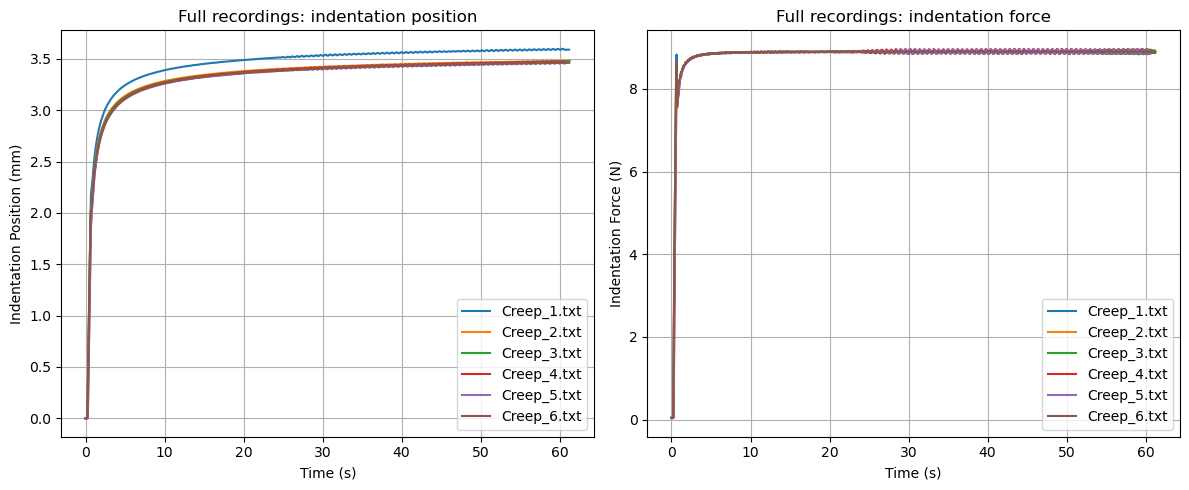

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for file, data in extracted:
    time = [float(row[0]) for row in data]
    position = [float(row[1]) for row in data]
    force = [float(row[2]) for row in data]

    axes[0].plot(time, position, label=file.name)
    axes[1].plot(time, force, label=file.name)

# Position subplot
axes[0].set_title('Full recordings: indentation position')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Indentation Position (mm)')
axes[0].legend()
axes[0].grid(True)

# Force subplot
axes[1].set_title('Full recordings: indentation force')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Indentation Force (N)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
plt.close(fig)

## Select the export interval

With `ENABLE_STEADY_STATE_SEGMENTATION = False`, retain every sample from the first through the last timestamp. Skip PID detection, its settings, both `STEADY_*_OFFSET_S` adjustments, and the displacement and force selection plots. Continuous 200 Hz timestamps and finite sensor values are still required.

With `ENABLE_STEADY_STATE_SEGMENTATION = True`, apply the following PID steady-force selection. In either mode, set `EXPORT_DURATION_S` to a multiple of 0.005 s to retain that many seconds from the first selected sample. For example, `60.0` yields 12,000 rows with the last time value at 59.995 s. `None` retains the whole selected interval. The current steady-force intervals are shorter than 60 s, so choose a shorter duration in steady-state mode. A requested duration longer than the selected interval raises an error before export.

Estimate the holding force from the median of the last **5 s**. Over a full trailing **2 s** window, require the mean within **2%** of that level, a force standard deviation no greater than **5%** of the level, and an absolute regression slope no greater than **1% of the holding force per second**. The 2 s window spans several of the approximately 0.6 s PID oscillations in these recordings; the variation allowance does not require a flat instantaneous force. Adjust `PID_STEADY_STATE_SETTINGS` if the controller oscillation period or amplitude changes.

Confirm the conditions continuously for **1 s**, and start at the first qualifying window endpoint in that run. Retain one continuous interval through the recording end, or stop earlier at the beginning of a later sustained loss of stability. Brief fluctuations and all bounded oscillation samples remain. No pointwise force threshold is applied to exported rows. These TXT recordings contain no release segment, so `release_guard_s` is zero; if future recordings include unloading, bound the hold before applying this detector.

After automatic detection, `STEADY_START_OFFSET_S` and `STEADY_END_OFFSET_S` shift the start and end boundaries for every recording. Positive values delay a boundary; negative values advance it. For example, start `-0.5` and end `-1.0` include 0.5 s earlier and stop 1 s earlier than the detected interval. Both default to `0.0`. Apply offsets before limiting the interval with `EXPORT_DURATION_S`. Manual extensions can include non-steady force. The adjusted interval must remain within the recording, contain at least two samples, and contain no missing sensor values; invalid adjustments raise an error rather than being clipped. Selection uses the existing 200 Hz grid: the first retained timestamp is at or after the adjusted start, and the end is exclusive. Rerun selection and plotting after changing offsets. The manifest records detected boundaries, offsets, adjusted boundaries, and final export boundaries.

The rolling statistics select boundaries only. Force and displacement remain unchanged, with their original alignment and amplitude. A recording without a confirmed steady interval raises an error before any exports are written.

The selection plots show the full displacement profile above the corresponding full force profile for each recording, sharing the original time axis. Green shading marks the final export mask after applying boundary offsets and any `EXPORT_DURATION_S` limit; vertical lines mark its start and exclusive end.


In [77]:
if EXPORT_DURATION_S is not None and (
        not np.isfinite(EXPORT_DURATION_S) or EXPORT_DURATION_S < 2 / SAMPLING_HZ
        or not np.isclose(EXPORT_DURATION_S * SAMPLING_HZ,
                          round(EXPORT_DURATION_S * SAMPLING_HZ), rtol=0, atol=1e-8)):
    raise ValueError('EXPORT_DURATION_S must be at least two samples and a multiple of the sampling interval.')
if ENABLE_STEADY_STATE_SEGMENTATION and not np.isfinite(
        [STEADY_START_OFFSET_S, STEADY_END_OFFSET_S]).all():
    raise ValueError('Steady-state boundary offsets must be finite seconds.')

segment_label = 'steady-force' if ENABLE_STEADY_STATE_SEGMENTATION else 'full-recording'
steady_extracted = []
segmentation_results = []
manifest_rows = []
for txt_path, rows in extracted:
    values = np.asarray(rows, dtype=float)
    sync = pd.DataFrame({
        'time_s': values[:, 0],
        'displacement_mm': values[:, 1],
        'force_n': values[:, 2],
    })
    cycle = pd.DataFrame([{
        'cycle': 1, 'onset_s': values[0, 0],
        'release_s': values[-1, 0] + 1.0 / SAMPLING_HZ,
    }])
    try:
        bounds = (segment_force_steady_state(sync, cycle, **PID_STEADY_STATE_SETTINGS)
                  if ENABLE_STEADY_STATE_SEGMENTATION else cycle)
        if ENABLE_STEADY_STATE_SEGMENTATION:
            bounds['detected_steady_start_s'] = bounds.steady_start_s
            bounds['detected_steady_end_s'] = bounds.steady_end_s
            bounds['steady_start_s'] += STEADY_START_OFFSET_S
            bounds['steady_end_s'] += STEADY_END_OFFSET_S
        event = bounds.iloc[0]
        export_start = event.steady_start_s if ENABLE_STEADY_STATE_SEGMENTATION else event.onset_s
        export_end = event.steady_end_s if ENABLE_STEADY_STATE_SEGMENTATION else event.release_s
        if (not np.isfinite([export_start, export_end]).all()
                or export_start < event.onset_s or export_end > event.release_s
                or export_start >= export_end):
            raise ValueError('Adjusted export boundaries must lie within the recording and start before the end.')
        export_bounds = bounds
        if EXPORT_DURATION_S is not None:
            times = sync.time_s.to_numpy()
            first = np.searchsorted(times, export_start)
            available = np.searchsorted(times, export_end) - first
            samples = round(EXPORT_DURATION_S * SAMPLING_HZ)
            if available < samples:
                raise ValueError(f'Only {available / SAMPLING_HZ:g} s available; '
                                 f'EXPORT_DURATION_S requests {EXPORT_DURATION_S:g} s.')
            next_sample = first + samples
            export_end = (min(times[next_sample], export_end) if next_sample < len(times)
                          else export_end)
            export_bounds = bounds.copy()
            export_bounds['steady_end_s' if ENABLE_STEADY_STATE_SEGMENTATION else 'release_s'] = export_end
        _, frame = extract_indentation_cycles(
            sync, export_bounds, sampling_hz=SAMPLING_HZ,
            steady_only=ENABLE_STEADY_STATE_SEGMENTATION,
        )[0]
    except ValueError as exc:
        raise ValueError(f'{txt_path.name}: {exc}') from exc
    steady_extracted.append((txt_path, frame))
    segmentation_results.append(dict(path=txt_path, sync=sync, bounds=bounds, frame=frame,
                                     export_start_s=export_start, export_end_s=export_end))
    manifest_rows.append({
        'file': f'{txt_path.stem}.csv',
        'source_txt': str(txt_path.relative_to(PROJECT_ROOT)),
        'steady_state_segmentation': ENABLE_STEADY_STATE_SEGMENTATION,
        'export_scope': 'steady_force_only' if ENABLE_STEADY_STATE_SEGMENTATION else 'full_load',
        'export_start_s': export_start,
        'export_end_s': export_end,
        'original_start_s': values[0, 0], 'original_last_sample_s': values[-1, 0],
        'rows': len(frame), 'duration_s': frame[OUTPUT_COLUMNS[0]].iloc[-1],
        'sampling_hz': SAMPLING_HZ,
        'force_std_n': frame[OUTPUT_COLUMNS[2]].std(ddof=0),
        'force_peak_to_peak_n': np.ptp(frame[OUTPUT_COLUMNS[2]].to_numpy()),
        'position_sign': EXTRACT_COLUMNS_SIGNS[1], 'force_sign': EXTRACT_COLUMNS_SIGNS[2],
        **({
            'detected_steady_start_s': event.detected_steady_start_s,
            'detected_steady_end_s': event.detected_steady_end_s,
            'steady_start_offset_s': STEADY_START_OFFSET_S,
            'steady_end_offset_s': STEADY_END_OFFSET_S,
            'steady_start_s': event.steady_start_s, 'steady_end_s': event.steady_end_s,
            'steady_force_n': event.steady_force_n,
            **{f'pid_{key}': value for key, value in PID_STEADY_STATE_SETTINGS.items()},
        } if ENABLE_STEADY_STATE_SEGMENTATION else {}),
    })

steady_summary = pd.DataFrame(manifest_rows)
display(steady_summary[['file', 'export_scope', 'export_start_s', 'export_end_s',
                        'force_std_n', 'rows', 'duration_s']])

,file,export_scope,export_start_s,export_end_s,force_std_n,rows,duration_s
0,Creep_1.csv,steady_force_only,8.820,58.820,0.023961,10000,49.995
1,Creep_2.csv,steady_force_only,8.850,58.850,0.008642,10000,49.995
2,Creep_3.csv,steady_force_only,8.815,58.815,0.014701,10000,49.995
3,Creep_4.csv,steady_force_only,8.835,58.835,0.032905,10000,49.995
4,Creep_5.csv,steady_force_only,8.875,58.875,0.031425,10000,49.995
5,Creep_6.csv,steady_force_only,8.805,58.805,0.008623,10000,49.995


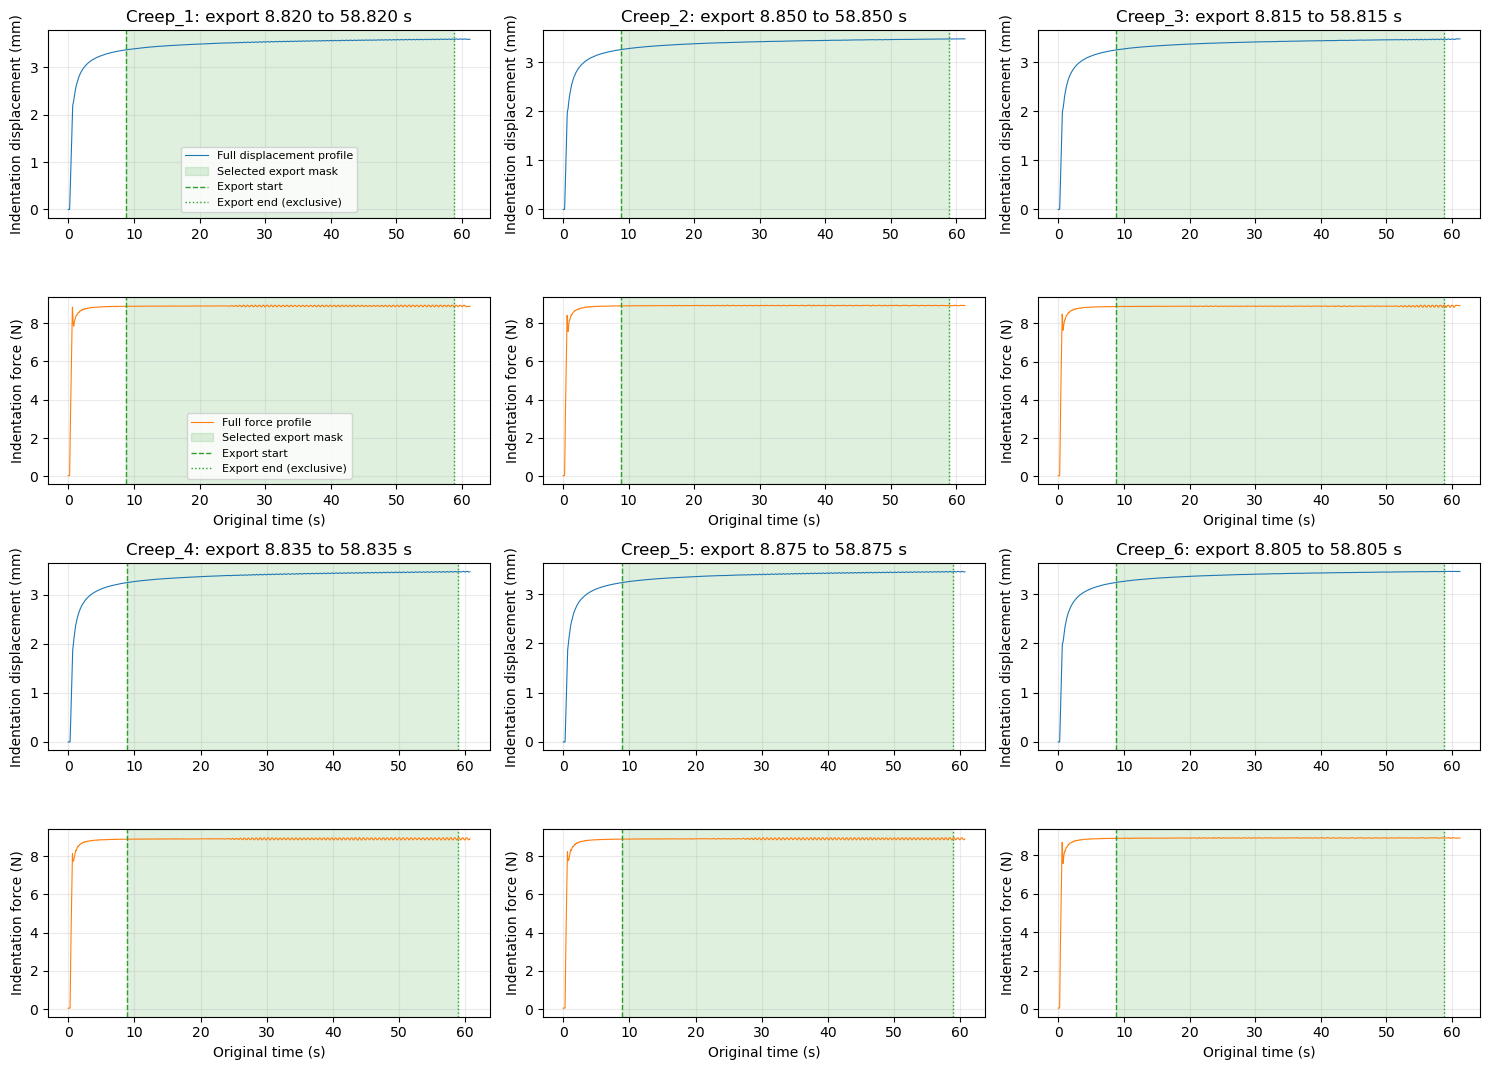

In [78]:
if ENABLE_STEADY_STATE_SEGMENTATION:
    ncols = min(3, len(segmentation_results))
    nrows = math.ceil(len(segmentation_results) / ncols)
    fig, axes = plt.subplots(2 * nrows, ncols, figsize=(5 * ncols, 5.4 * nrows), squeeze=False)
    for index, result in enumerate(segmentation_results):
        row, column = divmod(index, ncols)
        displacement_axis = axes[2 * row, column]
        force_axis = axes[2 * row + 1, column]
        force_axis.sharex(displacement_axis)
        sync = result['sync']
        start, end = result['export_start_s'], result['export_end_s']
        displacement_axis.plot(sync.time_s, sync.displacement_mm, lw=0.8,
                               color='tab:blue', label='Full displacement profile')
        force_axis.plot(sync.time_s, sync.force_n, lw=0.8,
                        color='tab:orange', label='Full force profile')
        displacement_axis.set(title=f"{result['path'].stem}: export {start:.3f} to {end:.3f} s",
                              ylabel='Indentation displacement (mm)')
        force_axis.set(xlabel='Original time (s)', ylabel='Indentation force (N)')
        for axis in (displacement_axis, force_axis):
            axis.axvspan(start, end, color='tab:green', alpha=0.15, label='Selected export mask')
            axis.axvline(start, color='tab:green', ls='--', lw=1, label='Export start')
            axis.axvline(end, color='tab:green', ls=':', lw=1, label='Export end (exclusive)')
            axis.grid(True, alpha=0.25)
    axes[0, 0].legend(fontsize=8)
    axes[1, 0].legend(fontsize=8)
    for index in range(len(segmentation_results), nrows * ncols):
        row, column = divmod(index, ncols)
        axes[2 * row, column].set_visible(False)
        axes[2 * row + 1, column].set_visible(False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


## Inspect retained force and displacement

The comparison below uses only the selected intervals, with time zero at the first retained sample in either mode. Force oscillations are intentionally visible and preserved. No displacement offset is removed, and position and force always retain the same sample count and timestamps.

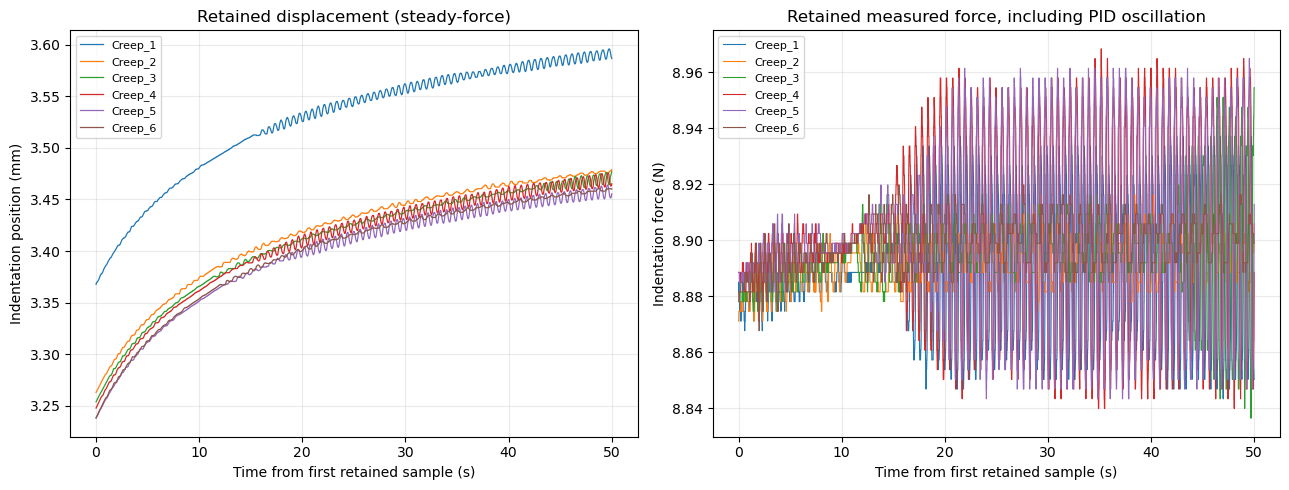

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for txt_path, frame in steady_extracted:
    time = frame[OUTPUT_COLUMNS[0]]
    line, = axes[0].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, label=txt_path.stem)
    axes[1].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, color=line.get_color(), label=txt_path.stem)
axes[0].set(title=f'Retained displacement ({segment_label})', ylabel='Indentation position (mm)')
axes[1].set(title='Retained measured force, including PID oscillation', ylabel='Indentation force (N)')
for axis in axes:
    axis.set_xlabel('Time from first retained sample (s)')
    axis.grid(True, alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## Export selected intervals

All inputs and selected intervals are validated before writing. Each CSV contains exactly the three configured columns without a row index. Running this cell overwrites matching exports and writes `_steady_state_manifest.csv` with the selected mode, original export boundaries (end exclusive), measured variation, and sampling rate. Detected and adjusted steady boundaries, boundary offsets, holding force, and PID detection settings are recorded only when segmentation is enabled. The adjusted `steady_start_s` and `steady_end_s` precede any `EXPORT_DURATION_S` limit; `export_start_s` and `export_end_s` describe the final retained interval. Raw TXT measurements remain untouched.

Steady-only exports start under load. A downstream model that assumes an unloaded initial reference or relaxed viscoelastic states must account for the preceding load history before using these steady-only exports.

In [80]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_summary = []
for txt_path, frame in steady_extracted:
    csv_path = OUTPUT_DIR / f'{txt_path.stem}.csv'
    with csv_path.open('w', encoding='utf-8', newline='') as handle:
        writer = csv.writer(handle, lineterminator='\n')
        writer.writerow(OUTPUT_COLUMNS)
        writer.writerows(frame.itertuples(index=False, name=None))
    export_summary.append({'file': csv_path.name, 'rows': len(frame), 'columns': len(OUTPUT_COLUMNS)})
    print(f'{txt_path.name} -> {csv_path.name}: {len(frame):,} {segment_label} rows x {len(OUTPUT_COLUMNS)} columns')

manifest_path = OUTPUT_DIR / '_steady_state_manifest.csv'
steady_summary.to_csv(manifest_path, index=False)
print(f'\nDone: exported {len(export_summary)} {segment_label} CSV files to {OUTPUT_DIR}')
print(f'Segmentation metadata: {manifest_path.name}')

Creep_1.txt -> Creep_1.csv: 10,000 steady-force rows x 3 columns
Creep_2.txt -> Creep_2.csv: 10,000 steady-force rows x 3 columns
Creep_3.txt -> Creep_3.csv: 10,000 steady-force rows x 3 columns
Creep_4.txt -> Creep_4.csv: 10,000 steady-force rows x 3 columns
Creep_5.txt -> Creep_5.csv: 10,000 steady-force rows x 3 columns
Creep_6.txt -> Creep_6.csv: 10,000 steady-force rows x 3 columns

Done: exported 6 steady-force CSV files to /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data
Segmentation metadata: _steady_state_manifest.csv


## Preview the first 5 rows of the first CSV

In [81]:
preview_path = OUTPUT_DIR / export_summary[0]['file']
with preview_path.open('r', encoding='utf-8', newline='') as handle:
    reader = csv.reader(handle)
    preview_header = next(reader)
    print(' | '.join(preview_header))
    for _, row in zip(range(5), reader):
        print(' | '.join(row))

Time, s | Indentation Position, mm | Indentation Force, N
0.0 | 3.367671 | 8.881592
0.005 | 3.367884 | 8.881592
0.01 | 3.368105 | 8.88506
0.015 | 3.368344 | 8.88506
0.02 | 3.368586 | 8.88506
